In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("logistica_baja_california.csv")
df.head(10)


,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero
5,32.536176,-117.031669,Entrega_Paquete
6,32.490330,-117.061402,Recoleccion
7,32.546237,-117.060305,Viaje_Pasajero
8,32.526208,-117.047032,Entrega_Paquete
9,32.527172,-117.021078,Viaje_Pasajero


In [2]:
df_logistica_bc = df[["Latitud", "Longitud"]]

scaler = StandardScaler()

X_matrix = scaler.fit_transform(df_logistica_bc)
print(X_matrix)

[[ 0.88335238 -0.73514142]
 [ 1.00618974 -0.94540065]
 [ 0.72294016 -1.00890342]
 ...
 [-4.40047914  3.45447951]
 [-4.3579893   3.2636921 ]
 [-4.41124399  3.35464997]]


1. ¿Que algoritmo de los vistos en clase se adecua mas a este problema?
K-means (n_clusters=3)

2. ¿Dónde colocó el algoritmo que seleccionaron las Cedis? 

3.¿Consideran que sus localizaciones hacen sentido?


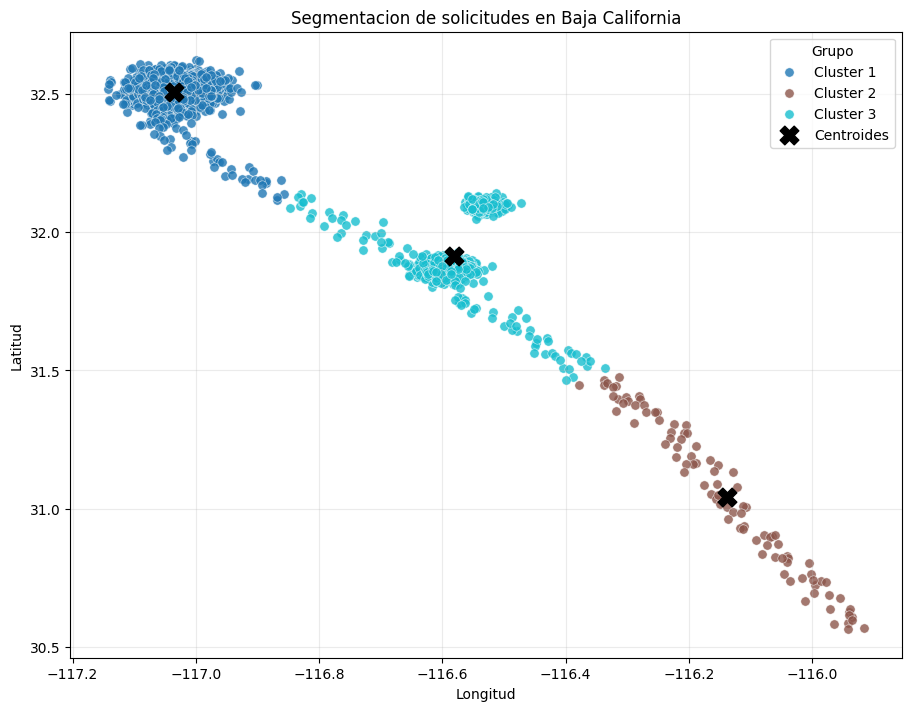

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

numero_clusters = 3
modelo_kmeans = KMeans(n_clusters=numero_clusters, random_state=42, n_init=10)
etiquetas_cluster = modelo_kmeans.fit_predict(X_matrix)
centroides = scaler.inverse_transform(modelo_kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
colores = plt.get_cmap("tab10", numero_clusters)

for cluster in range(numero_clusters):
    seleccion = etiquetas_cluster == cluster
    ax.scatter(
        df_logistica_bc.loc[seleccion, "Longitud"],
        df_logistica_bc.loc[seleccion, "Latitud"],
        color=colores(cluster),
        label=f"Cluster {cluster + 1}",
        s=45,
        alpha=0.8,
        edgecolors="white",
        linewidths=0.4,
    )

ax.scatter(
    centroides[:, 1],
    centroides[:, 0],
    color="black",
    marker="X",
    s=180,
    label="Centroides",
    zorder=3,
)
ax.set_title("Segmentacion de solicitudes en Baja California")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(True, alpha=0.25)
ax.legend(title="Grupo", loc="best")
plt.show()